In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten # 'layers' (plural) and 'MaxPooling2D' (camel case)
import numpy as np
import os
import matplotlib.pyplot as plt
import random


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
x_train = np.loadtxt(os.path.join('/content/drive/MyDrive/cnn', "input.csv"), delimiter=',')

y_train = np.loadtxt(os.path.join('/content/drive/MyDrive/cnn', "labels.csv"), delimiter=',')

x_test = np.loadtxt(os.path.join('/content/drive/MyDrive/cnn', "input_test.csv"), delimiter=',')
y_test = np.loadtxt(os.path.join('/content/drive/MyDrive/cnn', "labels_test.csv"), delimiter=',')

print("All files loaded successfully!")
print(f"Shape of x_train: {x_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of x_test: {x_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

All files loaded successfully!
Shape of x_train: (2000, 30000)
Shape of y_train: (2000,)
Shape of x_test: (400, 30000)
Shape of y_test: (400,)


In [17]:
x_train =x_train.reshape(len(x_train),100,100,3)
y_train =y_train.reshape(len(y_train),1)

x_test = x_test.reshape(len(x_test),100,100,3)
y_test = y_test.reshape(len(y_test),1)

x_train = x_train/255.0
x_test = x_test/255.0

In [18]:
print(f"Shape of x_train: {x_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of x_test: {x_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of x_train: (2000, 100, 100, 3)
Shape of y_train: (2000, 1)
Shape of x_test: (400, 100, 100, 3)
Shape of y_test: (400, 1)


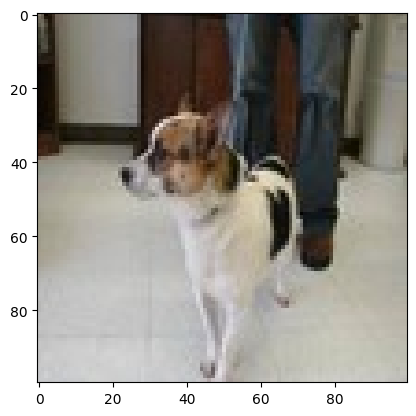

In [19]:
idx=random.randint(0,len(x_train))
plt.imshow(x_train[idx,:])
y_train[idx]
plt.show()

## **Model**


In [20]:
model=Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(100,100,3)),
    MaxPooling2D((2,2)),

    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(64,activation='relu'),
    Dense(1,activation='sigmoid')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
model = Sequential()

model.add(Conv2D(32,(3,3),activation='relu',input_shape=(100,100,3)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(32,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())
model.add(Dense(64,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [22]:
# opt=keras.optimizers.SGD(learning_rate=0.001)
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [23]:
model.fit(x_train,y_train,epochs=5,batch_size=64)

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 638ms/step - accuracy: 0.5179 - loss: 0.7180
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 698ms/step - accuracy: 0.5934 - loss: 0.6600
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 41s 703ms/step - accuracy: 0.6530 - loss: 0.6279
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 41s 702ms/step - accuracy: 0.7501 - loss: 0.5257
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 641ms/step - accuracy: 0.7862 - loss: 0.4517


In [24]:
model.evaluate(x_test,y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.7725 - loss: 0.4885


[0.5813423991203308, 0.7074999809265137]

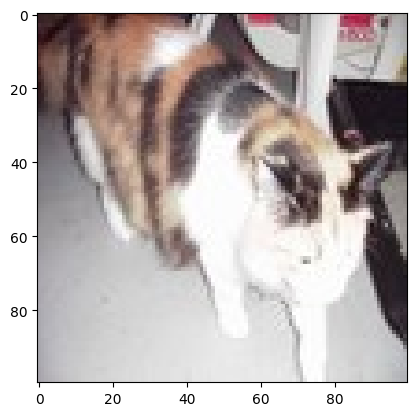

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
Our model says it is a : cat


In [25]:
idx2 = random.randint(0, len(y_test))
plt.imshow(x_test[idx2, :])
plt.show()

y_pred = model.predict(x_test[idx2, :].reshape(1, 100, 100, 3))
y_pred = y_pred > 0.5

if(y_pred == 0):
    pred = 'dog'
else:
    pred = 'cat'

print("Our model says it is a :", pred)

**Thank You**